# 02 · Exploratory Data Analysis

Questions this notebook answers:
1. How is revenue trending, and how seasonal is the business?
2. When do customers order (day × hour)?
3. Which categories and products drive revenue, and is it concentrated (Pareto)?
4. How concentrated is revenue across customers?
5. Where are customers located?
6. What gets returned?
7. Do new customers come back (cohort retention)?

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config as C
from src import io
from src import viz
from src.viz import PALETTE

viz.set_style()
t = io.load_all()
sales, returns, customers, products, countries = (
    t["sales"], t["returns"], t["customers"], t["products"], t["countries"])
sales = sales.merge(products[["stock_code", "description", "category"]], on="stock_code", how="left")
returns = returns.merge(products[["stock_code", "description", "category"]], on="stock_code", how="left")
known = sales[sales.customer_id != C.GUEST_CUSTOMER_ID]
print(f"{len(sales):,} sales lines | {sales.invoice_no.nunique():,} orders | {known.customer_id.nunique():,} customers")

1,003,340 sales lines | 39,516 orders | 5,852 customers


## 1. Revenue trend and seasonality
Net revenue = sales − returns. **December 2011 is a partial month** (data ends
on the 9th), so it is shaded and excluded from growth comparisons.

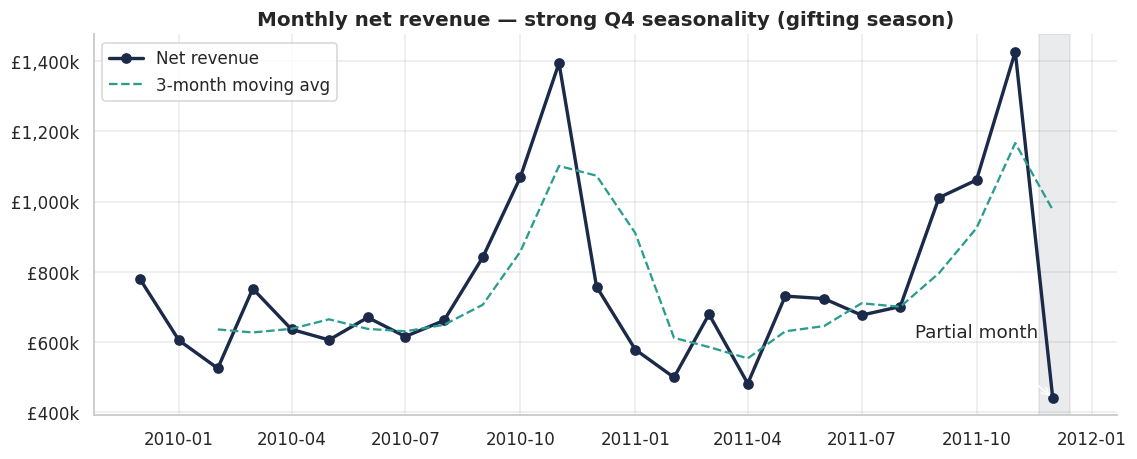

In [2]:
month = lambda s: s.dt.to_period("M").dt.to_timestamp()
monthly = pd.DataFrame({
    "gross": sales.groupby(month(sales.invoice_datetime))["line_value"].sum(),
    "returns": returns.groupby(month(returns.invoice_datetime))["line_value"].sum(),
    "orders": sales.groupby(month(sales.invoice_datetime))["invoice_no"].nunique(),
}).fillna(0)
monthly["net"] = monthly["gross"] - monthly["returns"]
monthly["aov"] = monthly["gross"] / monthly["orders"]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly["net"], marker="o", color=PALETTE["navy"], lw=2.2, label="Net revenue")
ax.plot(monthly.index, monthly["net"].rolling(3).mean(), ls="--", color=PALETTE["teal"], label="3-month moving avg")
ax.axvspan(pd.Timestamp("2011-11-20"), pd.Timestamp("2011-12-15"), color=PALETTE["slate"], alpha=0.15)
ax.annotate("Partial month", (pd.Timestamp("2011-12-01"), monthly["net"].iloc[-1]),
            xytext=(-90, 40), textcoords="offset points", arrowprops=dict(arrowstyle="->"))
viz.money_axis(ax)
ax.set_title("Monthly net revenue — strong Q4 seasonality (gifting season)")
ax.legend()
viz.save(fig, "01_monthly_net_revenue")
plt.show()

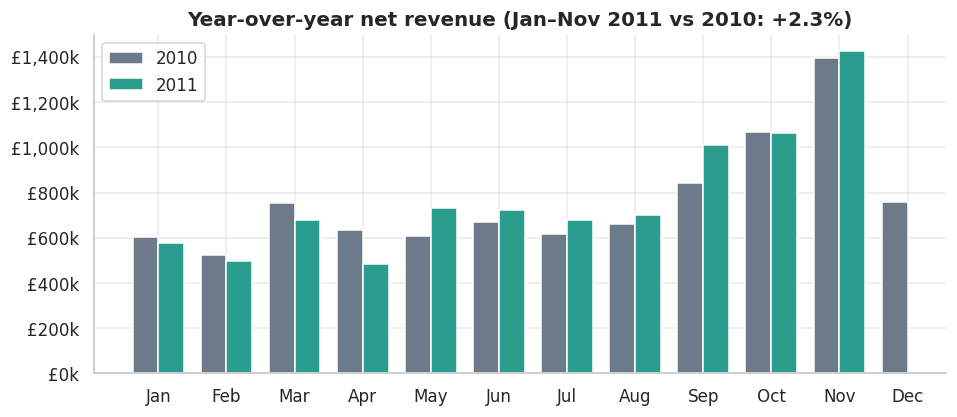

Sep–Dec share of 2010 net revenue: 44.5%


In [3]:
full = monthly.loc[:"2011-11-30"].copy()
full["year"], full["m"] = full.index.year, full.index.month
yoy = full.pivot_table(index="m", columns="year", values="net")
yoy_2011 = yoy.loc[1:11, 2011].sum() / yoy.loc[1:11, 2010].sum() - 1
q4_share = full.loc["2010-01-01":"2010-12-31"].query("m >= 9")["net"].sum() / full.loc["2010-01-01":"2010-12-31", "net"].sum()

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.38
ax.bar(yoy.index - w / 2, yoy[2010], w, label="2010", color=PALETTE["slate"])
ax.bar(yoy.index + w / 2, yoy[2011], w, label="2011", color=PALETTE["teal"])
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
viz.money_axis(ax)
ax.set_title(f"Year-over-year net revenue (Jan–Nov 2011 vs 2010: {yoy_2011:+.1%})")
ax.legend()
viz.save(fig, "02_yoy_revenue")
plt.show()
print(f"Sep–Dec share of 2010 net revenue: {q4_share:.1%}")

## 2. When do customers order?

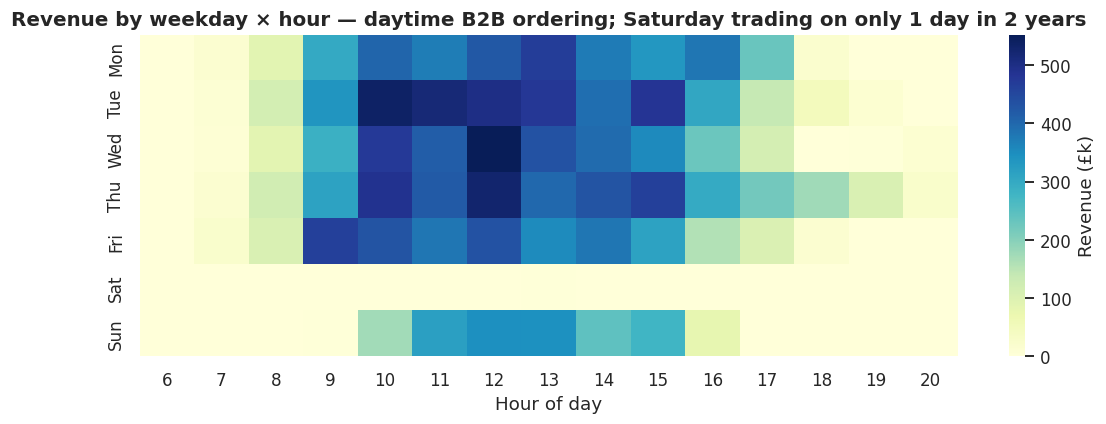

Distinct Saturdays with orders: 1


In [4]:
orders = (sales.groupby("invoice_no")
          .agg(dt=("invoice_datetime", "first"), value=("line_value", "sum"),
               customer_id=("customer_id", "first"), country=("country", "first")))
orders["dow"] = orders["dt"].dt.day_name().str[:3]
orders["hour"] = orders["dt"].dt.hour
heat = orders.pivot_table(index="dow", columns="hour", values="value", aggfunc="sum").fillna(0)
heat = heat.reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).dropna(how="all")

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(heat / 1e3, cmap="YlGnBu", ax=ax, cbar_kws={"label": f"Revenue ({C.CURRENCY}k)"})
ax.set_title("Revenue by weekday × hour — daytime B2B ordering; Saturday trading on only 1 day in 2 years")
ax.set_xlabel("Hour of day"); ax.set_ylabel("")
viz.save(fig, "03_weekday_hour_heatmap")
plt.show()
sat_days = orders.loc[orders.dow == "Sat", "dt"].dt.date.nunique()
print(f"Distinct Saturdays with orders: {sat_days}")

## 3. Categories, products and the Pareto principle

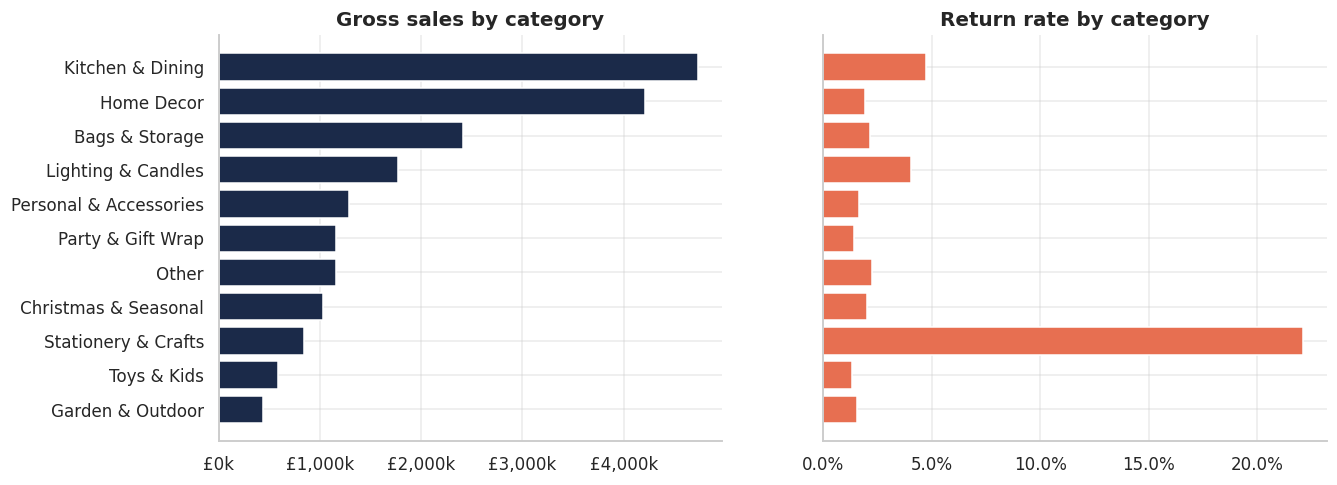

In [5]:
cat = (sales.groupby("category")["line_value"].sum().to_frame("gross")
       .join(returns.groupby("category")["line_value"].sum().rename("returns"))
       .fillna(0))
cat["return_rate"] = cat["returns"] / cat["gross"]
cat = cat.sort_values("gross")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
axes[0].barh(cat.index, cat["gross"], color=PALETTE["navy"])
viz.money_axis(axes[0], "x"); axes[0].set_title("Gross sales by category")
axes[1].barh(cat.index, cat["return_rate"], color=PALETTE["coral"])
viz.pct_axis(axes[1], "x"); axes[1].set_title("Return rate by category")
viz.save(fig, "04_category_sales_returns")
plt.show()

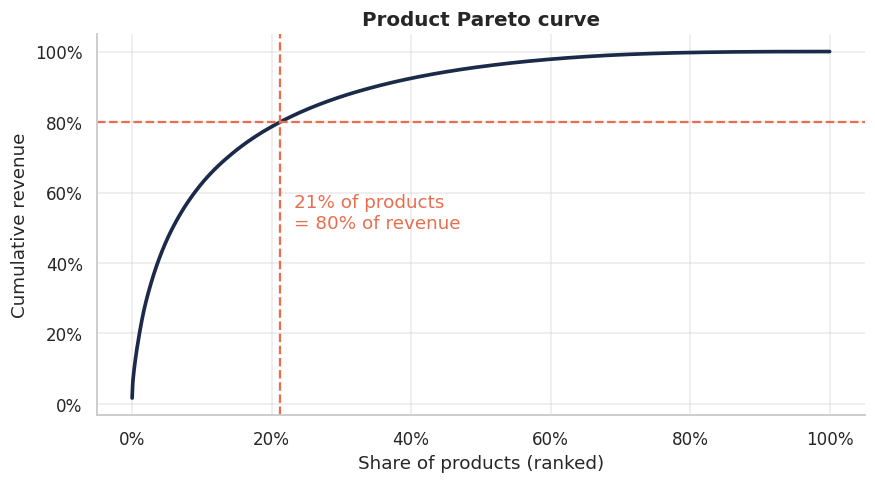

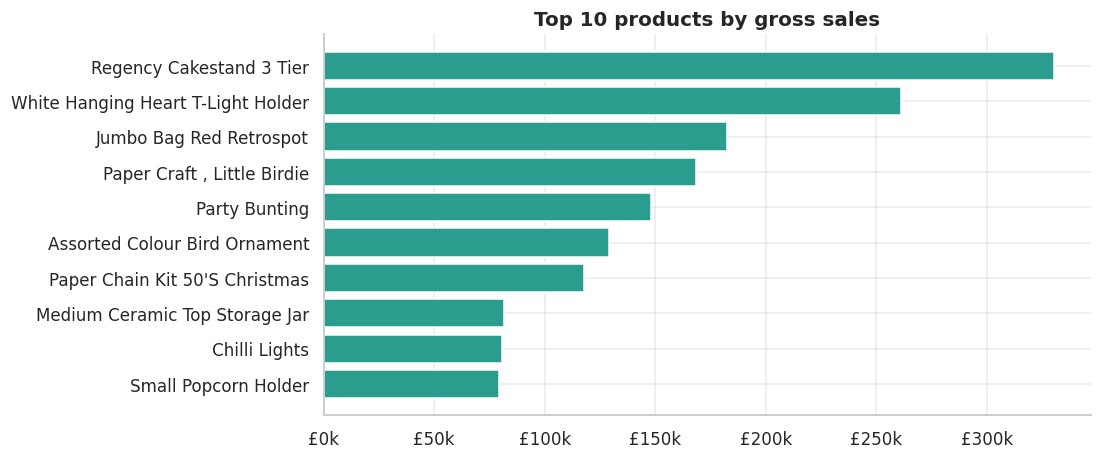

In [6]:
prod_rev = sales.groupby("stock_code")["line_value"].sum().sort_values(ascending=False)
cum = prod_rev.cumsum() / prod_rev.sum()
pct_products = np.arange(1, len(cum) + 1) / len(cum)
n80 = int((cum < 0.80).sum()) + 1
share_products_80 = n80 / len(cum)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(pct_products, cum.values, color=PALETTE["navy"], lw=2.4)
ax.axhline(0.8, ls="--", color=PALETTE["coral"]); ax.axvline(share_products_80, ls="--", color=PALETTE["coral"])
ax.text(share_products_80 + 0.02, 0.5, f"{share_products_80:.0%} of products\n= 80% of revenue", color=PALETTE["coral"])
viz.pct_axis(ax, "x"); viz.pct_axis(ax, "y")
ax.set_title("Product Pareto curve"); ax.set_xlabel("Share of products (ranked)"); ax.set_ylabel("Cumulative revenue")
viz.save(fig, "05_product_pareto")
plt.show()

top10 = (sales.groupby("description")["line_value"].sum().nlargest(10).sort_values())
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top10.index.str.title(), top10.values, color=PALETTE["teal"])
viz.money_axis(ax, "x"); ax.set_title("Top 10 products by gross sales")
viz.save(fig, "06_top10_products")
plt.show()

## 4. Customer concentration

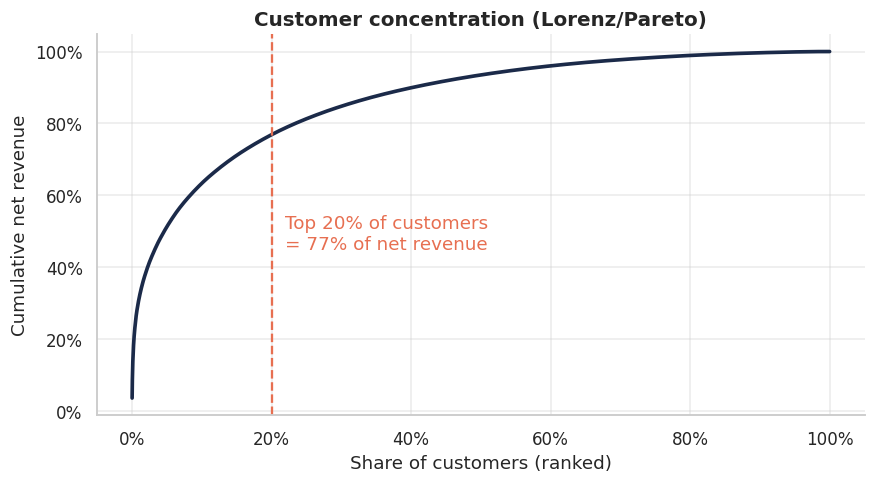

Top 20% of customers generate 76.9% of net revenue
23.4% of customers generate 80% of net revenue
One-time buyers: 27.6% of customers


In [7]:
cust_net = (known.groupby("customer_id")["line_value"].sum()
            .sub(returns.groupby("customer_id")["line_value"].sum(), fill_value=0)
            .loc[lambda s: s.index != 0].clip(lower=0).sort_values(ascending=False))
ccum = cust_net.cumsum() / cust_net.sum()
top20_share = ccum.iloc[int(len(ccum) * 0.20) - 1]
n_cust_80 = int((ccum < 0.80).sum()) + 1
share_cust_80 = n_cust_80 / len(ccum)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.arange(1, len(ccum) + 1) / len(ccum), ccum.values, color=PALETTE["navy"], lw=2.4)
ax.axvline(0.2, ls="--", color=PALETTE["coral"])
ax.text(0.22, 0.45, f"Top 20% of customers\n= {top20_share:.0%} of net revenue", color=PALETTE["coral"])
viz.pct_axis(ax, "x"); viz.pct_axis(ax, "y")
ax.set_title("Customer concentration (Lorenz/Pareto)"); ax.set_xlabel("Share of customers (ranked)"); ax.set_ylabel("Cumulative net revenue")
viz.save(fig, "07_customer_pareto")
plt.show()

freq = known.groupby("customer_id")["invoice_no"].nunique()
one_timers = (freq == 1).mean()
print(f"Top 20% of customers generate {top20_share:.1%} of net revenue")
print(f"{share_cust_80:.1%} of customers generate 80% of net revenue")
print(f"One-time buyers: {one_timers:.1%} of customers")

## 5. Geography

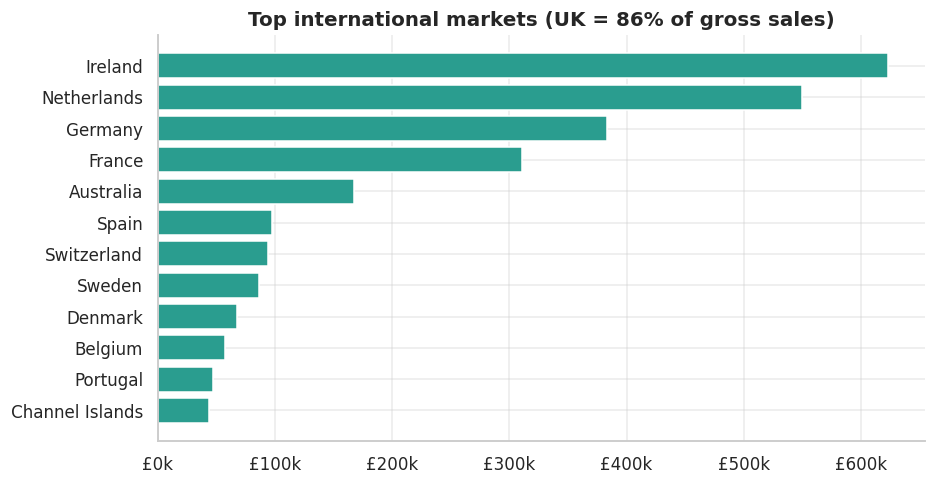

Average order value — UK: £464 | International: £853


In [8]:
geo = sales.groupby("country")["line_value"].sum().sort_values(ascending=False)
uk_share = geo["United Kingdom"] / geo.sum()
intl = geo.drop("United Kingdom").head(12).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(intl.index, intl.values, color=PALETTE["teal"])
viz.money_axis(ax, "x")
ax.set_title(f"Top international markets (UK = {uk_share:.0%} of gross sales)")
viz.save(fig, "08_top_international_markets")
plt.show()

intl_aov = orders.assign(intl=orders.country != "United Kingdom").groupby("intl")["value"].mean()
print(f"Average order value — UK: {C.CURRENCY}{intl_aov[False]:,.0f} | International: {C.CURRENCY}{intl_aov[True]:,.0f}")

## 6. Returns

In [9]:
ret_prod = (returns.groupby("description")["line_value"].sum().to_frame("returned")
            .join(sales.groupby("description")["line_value"].sum().rename("sold")))
ret_prod["return_rate"] = ret_prod["returned"] / ret_prod["sold"]
ret_prod.query("sold > 20000").sort_values("return_rate", ascending=False).head(10).style.format(
    {"returned": "£{:,.0f}", "sold": "£{:,.0f}", "return_rate": "{:.1%}"})

,returned,sold,return_rate
description,,,
"PAPER CRAFT , LITTLE BIRDIE","£168,470","£168,470",100.0%
MEDIUM CERAMIC TOP STORAGE JAR,"£77,480","£81,701",94.8%
FAIRY CAKE FLANNEL ASSORTED COLOUR,"£6,614","£25,407",26.0%
FELTCRAFT DOLL MOLLY,"£3,563","£20,151",17.7%
TEA TIME PARTY BUNTING,"£4,490","£27,565",16.3%
COLOUR GLASS. STAR T-LIGHT HOLDER,"£7,164","£44,681",16.0%
SET/4 WHITE RETRO STORAGE CUBES,"£5,188","£43,845",11.8%
DOORMAT FAIRY CAKE,"£4,679","£45,724",10.2%
CERAMIC CAKE STAND + HANGING CAKES,"£2,234","£22,333",10.0%


## 7. Cohort retention
Share of each monthly acquisition cohort that purchases again N months later.

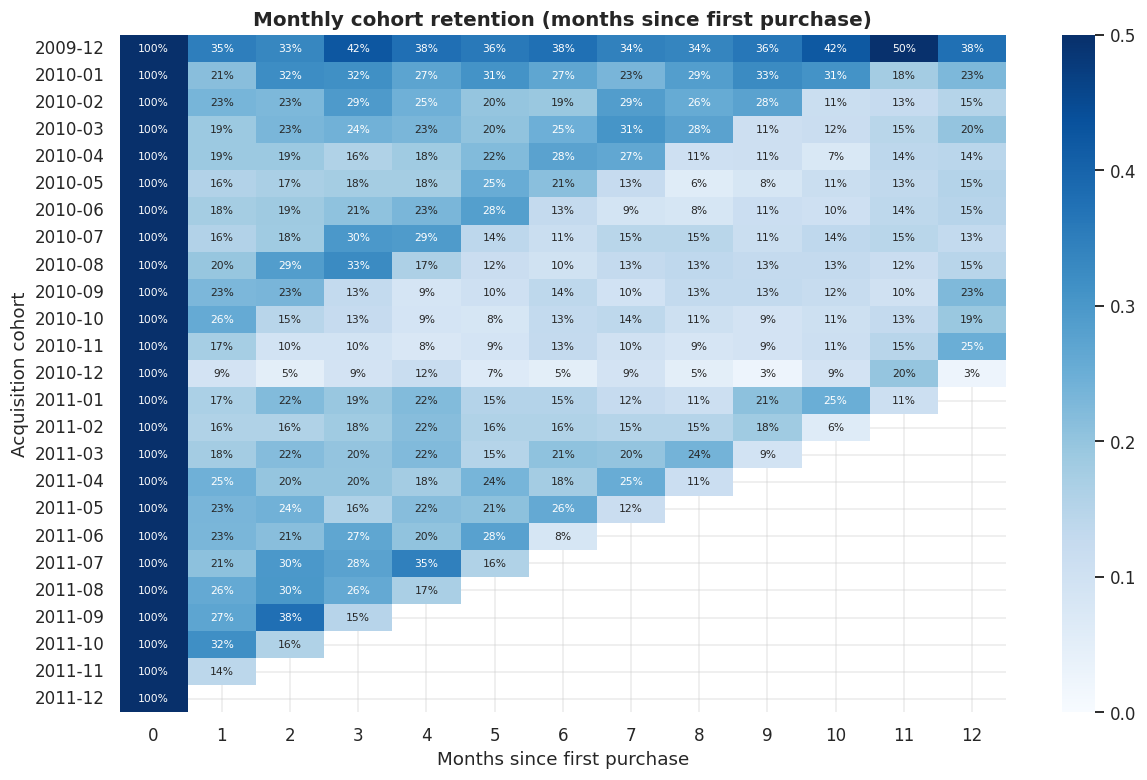

Avg retention — month 1: 21.0% | month 3: 21.7% | month 12: 18.3%
Dec-2009 cohort still buying after 12 months: 37.6%


In [10]:
cohort = (known.merge(customers[["customer_id", "cohort_month"]], on="customer_id")
          .groupby(["cohort_month", "cohort_index"])["customer_id"].nunique().unstack())
retention = cohort.div(cohort[0], axis=0)
retention.index = retention.index.strftime("%Y-%m")
ret_view = retention.iloc[:, :13]

fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(ret_view, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=0.5, ax=ax,
            cbar_kws={"format": "%.0f%%"} if False else {}, annot_kws={"size": 7})
ax.set_title("Monthly cohort retention (months since first purchase)")
ax.set_xlabel("Months since first purchase"); ax.set_ylabel("Acquisition cohort")
viz.save(fig, "09_cohort_retention")
plt.show()

m1 = retention[1].mean()
m3 = retention[3].mean()
m12 = retention[12].dropna().mean()
print(f"Avg retention — month 1: {m1:.1%} | month 3: {m3:.1%} | month 12: {m12:.1%}")
print(f"Dec-2009 cohort still buying after 12 months: {retention.loc['2009-12', 12]:.1%}")

**Caveat — left-censoring:** the data starts on 2009-12-01, so every customer who
had been buying *before* that date is labelled as a "Dec-2009 new customer".
That is why the 2009-12 row looks far more loyal than later cohorts. It is a
data-window artefact, not a sudden drop in customer quality. True new-customer
retention is better read from the 2010-01 cohort onwards (~15–25% monthly).

## Key EDA findings

In [11]:
eda_metrics = {
    "gross_sales": float(sales.line_value.sum()),
    "returns_value": float(returns.line_value.sum()),
    "net_revenue": float(sales.line_value.sum() - returns.line_value.sum()),
    "orders": int(sales.invoice_no.nunique()),
    "customers": int(known.customer_id.nunique()),
    "yoy_growth_jan_nov_2011": float(yoy_2011),
    "q4_share_2010": float(q4_share),
    "share_products_for_80pct_revenue": float(share_products_80),
    "top20_customers_revenue_share": float(top20_share),
    "share_customers_for_80pct_revenue": float(share_cust_80),
    "one_time_buyer_share": float(one_timers),
    "uk_share": float(uk_share),
    "aov_uk": float(intl_aov[False]), "aov_intl": float(intl_aov[True]),
    "retention_m1": float(m1), "retention_m3": float(m3), "retention_m12": float(m12),
}
io.update_metrics(eda_metrics)
for k, v in eda_metrics.items():
    print(f"{k:<36} {v:,.3f}" if isinstance(v, float) else f"{k:<36} {v:,}")

gross_sales                          19,643,861.620
returns_value                        716,425.970
net_revenue                          18,927,435.650
orders                               39,516
customers                            5,852
yoy_growth_jan_nov_2011              0.023
q4_share_2010                        0.445
share_products_for_80pct_revenue     0.213
top20_customers_revenue_share        0.769
share_customers_for_80pct_revenue    0.234
one_time_buyer_share                 0.276
uk_share                             0.855
aov_uk                               464.322
aov_intl                             853.194
retention_m1                         0.210
retention_m3                         0.217
retention_m12                        0.183
